# 🐼 Pandas Essentials for Data Science

A hands-on, well-documented walkthrough of the pandas features you will use in almost **every** data science project.

## What you'll learn
1. Pandas data structures: `Series` and `DataFrame`
2. Creating & loading data
3. Exploring & inspecting data
4. Selecting, filtering & indexing
5. Handling missing data
6. Adding, transforming & applying functions to columns
7. Sorting and ranking
8. Grouping & aggregating (`groupby`)
9. Merging, joining & concatenating
10. Pivot tables & reshaping (`pivot`, `melt`)
11. String operations
12. Working with dates & times
13. Quick visualization
14. Exporting data

> 💡 **Tip:** Run the cells in order — later sections build on DataFrames created earlier. Each code cell has comments, and each section starts with a markdown explanation of *why* it matters, not just *how* it works.


In [1]:
# Import the core libraries
import pandas as pd
import numpy as np

# Show more rows/columns by default so outputs aren't truncated
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 120)

print("pandas version:", pd.__version__)


pandas version: 3.0.2


## 1. Pandas Data Structures

Pandas has two core data structures:

- **`Series`** — a one-dimensional labeled array (think: a single column, or a list with an index attached).
- **`DataFrame`** — a two-dimensional labeled table (think: a spreadsheet or SQL table). It's basically a dictionary of `Series` that all share the same index.

Understanding the index (the row labels) is key — it's what makes pandas operations *align by label* instead of just by position.


In [2]:
# --- Series: a single labeled column of data ---
s = pd.Series([10, 20, 30, 40], index=['a', 'b', 'c', 'd'], name='sales')
print(s)
print()
print("Access by label:", s['b'])
print("Access by position:", s.iloc[1])


a    10
b    20
c    30
d    40
Name: sales, dtype: int64

Access by label: 20
Access by position: 20


In [3]:
# --- DataFrame: a labeled 2D table ---
# The most common way to build one: a dictionary of equal-length lists/arrays
data = {
    'name':   ['Alice', 'Bob', 'Charlie', 'Diana', 'Evan'],
    'age':    [25, 32, 18, 47, 29],
    'city':   ['Kathmandu', 'Pokhara', 'Kathmandu', 'Biratnagar', 'Pokhara'],
    'salary': [55000, 72000, 30000, 98000, 61000]
}
df = pd.DataFrame(data)
df


,name,age,city,salary
0,Alice,25,Kathmandu,55000
1,Bob,32,Pokhara,72000
2,Charlie,18,Kathmandu,30000
3,Diana,47,Biratnagar,98000
4,Evan,29,Pokhara,61000


## 2. Creating & Loading Data

Real projects usually start by **reading data from a file** rather than typing it in by hand. Pandas has one `read_*` function per format, and they all return a DataFrame. We'll create a small CSV on disk here so the notebook is fully self-contained and runnable offline.


In [4]:
# Save our example DataFrame to CSV, then read it back in — this mirrors
# what you'd do with a real dataset like 'sales.csv'
df.to_csv('people.csv', index=False)

df_from_csv = pd.read_csv('people.csv')
df_from_csv

# Other common readers you'll use on real projects:
# pd.read_excel('file.xlsx')
# pd.read_json('file.json')
# pd.read_sql(query, connection)
# pd.read_parquet('file.parquet')


,name,age,city,salary
0,Alice,25,Kathmandu,55000
1,Bob,32,Pokhara,72000
2,Charlie,18,Kathmandu,30000
3,Diana,47,Biratnagar,98000
4,Evan,29,Pokhara,61000


## 3. Exploring & Inspecting Data

Before doing anything else, **always look at your data first**. These are the methods you'll run within seconds of loading any new dataset.

| Method | What it tells you |
|---|---|
| `.head()` / `.tail()` | First / last N rows |
| `.shape` | (rows, columns) |
| `.info()` | column types + non-null counts |
| `.describe()` | summary statistics for numeric columns |
| `.columns` / `.dtypes` | column names / data types |
| `.isna().sum()` | count of missing values per column |


In [5]:
print("Shape (rows, columns):", df.shape)
print()
print("Column names:", list(df.columns))
print()
print("Data types:\n", df.dtypes)


Shape (rows, columns): (5, 4)

Column names: ['name', 'age', 'city', 'salary']

Data types:
 name        str
age       int64
city        str
salary    int64
dtype: object


In [6]:
# .head() shows the first N rows (default 5) — great for a quick sanity check
df.head(3)


,name,age,city,salary
0,Alice,25,Kathmandu,55000
1,Bob,32,Pokhara,72000
2,Charlie,18,Kathmandu,30000


In [7]:
# .info() is one of the most useful first commands: shows dtypes + non-null counts
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   name    5 non-null      str  
 1   age     5 non-null      int64
 2   city    5 non-null      str  
 3   salary  5 non-null      int64
dtypes: int64(2), str(2)
memory usage: 292.0 bytes


In [8]:
# .describe() gives summary statistics (count, mean, std, min, quartiles, max)
# for all numeric columns by default
df.describe()


,age,salary
count,5.000000,5.000000
mean,30.200000,63200.000000
std,10.756393,24813.302884
min,18.000000,30000.000000
25%,25.000000,55000.000000
50%,29.000000,61000.000000
75%,32.000000,72000.000000
max,47.000000,98000.000000


## 4. Selecting, Filtering & Indexing

This is the part of pandas you'll use most often. The key distinction:

- **`df['col']`** or **`df.col`** → select a column (returns a `Series`)
- **`df.loc[]`** → select by **label**
- **`df.iloc[]`** → select by **integer position**
- **Boolean masks** (`df[condition]`) → filter rows that meet a condition

> ⚠️ **Common pitfall:** `.loc` is *label*-based and its end of a slice is **inclusive**. `.iloc` is *position*-based like normal Python slicing (end is **exclusive**).


In [9]:
# Selecting a single column -> returns a Series
df['name']


0      Alice
1        Bob
2    Charlie
3      Diana
4       Evan
Name: name, dtype: str

In [10]:
# Selecting multiple columns -> pass a list, returns a DataFrame
df[['name', 'salary']]


,name,salary
0,Alice,55000
1,Bob,72000
2,Charlie,30000
3,Diana,98000
4,Evan,61000


In [11]:
# .loc: select by label — rows 1 to 3 (inclusive!) and specific columns
df.loc[1:3, ['name', 'age']]


,name,age
1,Bob,32
2,Charlie,18
3,Diana,47


In [12]:
# .iloc: select by integer position — rows 0 to 2 (exclusive of 3), first two columns
df.iloc[0:3, 0:2]


,name,age
0,Alice,25
1,Bob,32
2,Charlie,18


In [13]:
# Boolean filtering: the bread-and-butter of data analysis
# "Give me everyone earning more than 60,000"
high_earners = df[df['salary'] > 60000]
high_earners


,name,age,city,salary
1,Bob,32,Pokhara,72000
3,Diana,47,Biratnagar,98000
4,Evan,29,Pokhara,61000


In [14]:
# Combine multiple conditions with & (and) / | (or) — always wrap each condition in parentheses!
result = df[(df['salary'] > 50000) & (df['city'] == 'Kathmandu')]
result


,name,age,city,salary
0,Alice,25,Kathmandu,55000


In [15]:
# .isin() is handy for filtering against a list of allowed values
df[df['city'].isin(['Kathmandu', 'Pokhara'])]


,name,age,city,salary
0,Alice,25,Kathmandu,55000
1,Bob,32,Pokhara,72000
2,Charlie,18,Kathmandu,30000
4,Evan,29,Pokhara,61000


## 5. Handling Missing Data

Real-world data is messy. Pandas represents missing values as `NaN` (Not a Number). Key methods:

- **`isna()` / `notna()`** — detect missing values
- **`dropna()`** — remove rows/columns with missing values
- **`fillna()`** — fill missing values with a default, a computed value (like the mean), or forward/backward fill


In [16]:
# Introduce some missing values to demonstrate handling them
df_missing = df.copy()
df_missing.loc[1, 'age'] = np.nan
df_missing.loc[3, 'salary'] = np.nan
df_missing


,name,age,city,salary
0,Alice,25.0,Kathmandu,55000.0
1,Bob,NaN,Pokhara,72000.0
2,Charlie,18.0,Kathmandu,30000.0
3,Diana,47.0,Biratnagar,NaN
4,Evan,29.0,Pokhara,61000.0


In [17]:
# Count missing values per column — the very first thing to check
df_missing.isna().sum()


name      0
age       1
city      0
salary    1
dtype: int64

In [18]:
# Drop rows that have ANY missing value
df_missing.dropna()


,name,age,city,salary
0,Alice,25.0,Kathmandu,55000.0
2,Charlie,18.0,Kathmandu,30000.0
4,Evan,29.0,Pokhara,61000.0


In [19]:
# Fill missing values — here we fill 'age' with the column mean and
# 'salary' with 0, showing two different strategies in one call
df_filled = df_missing.fillna({
    'age': df_missing['age'].mean(),
    'salary': 0
})
df_filled


,name,age,city,salary
0,Alice,25.00,Kathmandu,55000.0
1,Bob,29.75,Pokhara,72000.0
2,Charlie,18.00,Kathmandu,30000.0
3,Diana,47.00,Biratnagar,0.0
4,Evan,29.00,Pokhara,61000.0


## 6. Adding, Transforming & Applying Functions to Columns

You'll constantly need to create new columns from existing ones. Pandas is **vectorized** — operations on whole columns are fast and idiomatic. Use `.apply()` when you need custom, row-by-row logic that can't easily be vectorized.


In [20]:
# Vectorized column creation — fast, and the preferred approach whenever possible
df['salary_in_thousands'] = df['salary'] / 1000
df


,name,age,city,salary,salary_in_thousands
0,Alice,25,Kathmandu,55000,55.0
1,Bob,32,Pokhara,72000,72.0
2,Charlie,18,Kathmandu,30000,30.0
3,Diana,47,Biratnagar,98000,98.0
4,Evan,29,Pokhara,61000,61.0


In [21]:
# .apply() with a lambda for custom, non-vectorizable logic
# Here: categorize age into a life-stage bucket
def age_bucket(age):
    if age < 25:
        return 'Young'
    elif age < 40:
        return 'Adult'
    else:
        return 'Senior'

df['age_group'] = df['age'].apply(age_bucket)
df


,name,age,city,salary,salary_in_thousands,age_group
0,Alice,25,Kathmandu,55000,55.0,Adult
1,Bob,32,Pokhara,72000,72.0,Adult
2,Charlie,18,Kathmandu,30000,30.0,Young
3,Diana,47,Biratnagar,98000,98.0,Senior
4,Evan,29,Pokhara,61000,61.0,Adult


In [22]:
# map() is a lighter-weight cousin of apply(), great for simple value substitution
city_region = {'Kathmandu': 'Bagmati', 'Pokhara': 'Gandaki', 'Biratnagar': 'Koshi'}
df['region'] = df['city'].map(city_region)
df


,name,age,city,salary,salary_in_thousands,age_group,region
0,Alice,25,Kathmandu,55000,55.0,Adult,Bagmati
1,Bob,32,Pokhara,72000,72.0,Adult,Gandaki
2,Charlie,18,Kathmandu,30000,30.0,Young,Bagmati
3,Diana,47,Biratnagar,98000,98.0,Senior,Koshi
4,Evan,29,Pokhara,61000,61.0,Adult,Gandaki


## 7. Sorting and Ranking

Use `.sort_values()` to order rows by one or more columns, and `.sort_index()` to order by the index.


In [23]:
# Sort by a single column, descending
df.sort_values('salary', ascending=False)


,name,age,city,salary,salary_in_thousands,age_group,region
3,Diana,47,Biratnagar,98000,98.0,Senior,Koshi
1,Bob,32,Pokhara,72000,72.0,Adult,Gandaki
4,Evan,29,Pokhara,61000,61.0,Adult,Gandaki
0,Alice,25,Kathmandu,55000,55.0,Adult,Bagmati
2,Charlie,18,Kathmandu,30000,30.0,Young,Bagmati


In [24]:
# Sort by multiple columns: city ascending, then salary descending within each city
df.sort_values(['city', 'salary'], ascending=[True, False])


,name,age,city,salary,salary_in_thousands,age_group,region
3,Diana,47,Biratnagar,98000,98.0,Senior,Koshi
0,Alice,25,Kathmandu,55000,55.0,Adult,Bagmati
2,Charlie,18,Kathmandu,30000,30.0,Young,Bagmati
1,Bob,32,Pokhara,72000,72.0,Adult,Gandaki
4,Evan,29,Pokhara,61000,61.0,Adult,Gandaki


## 8. Grouping & Aggregating — `groupby`

`groupby` follows the classic **split → apply → combine** pattern:
1. **Split** the data into groups based on some key (e.g. `city`)
2. **Apply** an aggregation function to each group (e.g. `mean`)
3. **Combine** the results back into a single output

This is the single most powerful tool in pandas for summarizing data.


In [25]:
# Average salary per city
df.groupby('city')['salary'].mean()


city
Biratnagar    98000.0
Kathmandu     42500.0
Pokhara       66500.0
Name: salary, dtype: float64

In [26]:
# Multiple aggregations at once with .agg()
df.groupby('city').agg(
    avg_salary=('salary', 'mean'),
    max_salary=('salary', 'max'),
    num_people=('name', 'count')
)


,avg_salary,max_salary,num_people
city,,,
Biratnagar,98000.0,98000,1
Kathmandu,42500.0,55000,2
Pokhara,66500.0,72000,2


In [27]:
# Group by multiple keys
df.groupby(['city', 'age_group'])['salary'].mean()


city        age_group
Biratnagar  Senior       98000.0
Kathmandu   Adult        55000.0
            Young        30000.0
Pokhara     Adult        66500.0
Name: salary, dtype: float64

## 9. Merging, Joining & Concatenating

You'll frequently need to combine data from multiple tables/DataFrames:

- **`pd.merge()`** — SQL-style joins (`inner`, `left`, `right`, `outer`) on a common key
- **`pd.concat()`** — stack DataFrames on top of each other (rows) or side-by-side (columns)


In [28]:
# Create a second table to merge with our main DataFrame
department = pd.DataFrame({
    'name': ['Alice', 'Bob', 'Charlie', 'Frank'],
    'department': ['Engineering', 'Sales', 'Engineering', 'HR']
})
department


,name,department
0,Alice,Engineering
1,Bob,Sales
2,Charlie,Engineering
3,Frank,HR


In [29]:
# Inner join: keep only names that exist in BOTH DataFrames
pd.merge(df, department, on='name', how='inner')


,name,age,city,salary,salary_in_thousands,age_group,region,department
0,Alice,25,Kathmandu,55000,55.0,Adult,Bagmati,Engineering
1,Bob,32,Pokhara,72000,72.0,Adult,Gandaki,Sales
2,Charlie,18,Kathmandu,30000,30.0,Young,Bagmati,Engineering


In [30]:
# Left join: keep ALL rows from df, filling with NaN where there's no match
pd.merge(df, department, on='name', how='left')


,name,age,city,salary,salary_in_thousands,age_group,region,department
0,Alice,25,Kathmandu,55000,55.0,Adult,Bagmati,Engineering
1,Bob,32,Pokhara,72000,72.0,Adult,Gandaki,Sales
2,Charlie,18,Kathmandu,30000,30.0,Young,Bagmati,Engineering
3,Diana,47,Biratnagar,98000,98.0,Senior,Koshi,NaN
4,Evan,29,Pokhara,61000,61.0,Adult,Gandaki,NaN


In [31]:
# concat: stack two DataFrames vertically (e.g. combining monthly data files)
more_people = pd.DataFrame({
    'name': ['Grace', 'Heidi'],
    'age': [41, 22],
    'city': ['Lalitpur', 'Kathmandu'],
    'salary': [83000, 45000]
})
combined = pd.concat([df[['name', 'age', 'city', 'salary']], more_people], ignore_index=True)
combined


,name,age,city,salary
0,Alice,25,Kathmandu,55000
1,Bob,32,Pokhara,72000
2,Charlie,18,Kathmandu,30000
3,Diana,47,Biratnagar,98000
4,Evan,29,Pokhara,61000
5,Grace,41,Lalitpur,83000
6,Heidi,22,Kathmandu,45000


## 10. Pivot Tables & Reshaping

- **`pivot_table()`** — summarize data into a spreadsheet-style table (rows × columns × aggregated values)
- **`melt()`** — the opposite: turn wide data into long/tidy format, often needed before plotting or modeling


In [32]:
# Pivot table: average salary by city (rows) and age_group (columns)
pivot = df.pivot_table(values='salary', index='city', columns='age_group', aggfunc='mean')
pivot


age_group,Adult,Senior,Young
city,,,
Biratnagar,NaN,98000.0,NaN
Kathmandu,55000.0,NaN,30000.0
Pokhara,66500.0,NaN,NaN


In [33]:
# melt: reshape from wide to long format ("tidy data")
wide = pd.DataFrame({
    'name': ['Alice', 'Bob'],
    'math_score': [85, 78],
    'science_score': [90, 82]
})
long = wide.melt(id_vars='name', var_name='subject', value_name='score')
long


,name,subject,score
0,Alice,math_score,85
1,Bob,math_score,78
2,Alice,science_score,90
3,Bob,science_score,82


## 11. String Operations

Text columns often need cleaning. Pandas exposes vectorized string methods through the **`.str`** accessor — much faster than looping in Python.


In [34]:
# .str gives access to vectorized string methods, similar to Python's built-in str methods
df['name_upper'] = df['name'].str.upper()
df['name_length'] = df['name'].str.len()
df['starts_with_a'] = df['name'].str.lower().str.startswith('a')
df[['name', 'name_upper', 'name_length', 'starts_with_a']]


,name,name_upper,name_length,starts_with_a
0,Alice,ALICE,5,True
1,Bob,BOB,3,False
2,Charlie,CHARLIE,7,False
3,Diana,DIANA,5,False
4,Evan,EVAN,4,False


## 12. Working with Dates & Times

Use `pd.to_datetime()` to convert text/columns into proper datetime objects — this unlocks powerful `.dt` accessor methods and time-based indexing/resampling.


In [35]:
# Create a date column and convert it to datetime
df['hire_date'] = pd.to_datetime(['2019-03-14', '2021-07-01', '2023-01-10', '2015-11-23', '2020-05-30'])

# .dt accessor exposes date components
df['hire_year'] = df['hire_date'].dt.year
df['days_employed'] = (pd.Timestamp.today() - df['hire_date']).dt.days

df[['name', 'hire_date', 'hire_year', 'days_employed']]


,name,hire_date,hire_year,days_employed
0,Alice,2019-03-14,2019,2715
1,Bob,2021-07-01,2021,1875
2,Charlie,2023-01-10,2023,1317
3,Diana,2015-11-23,2015,3922
4,Evan,2020-05-30,2020,2272


## 13. Quick Visualization

Pandas DataFrames have a built-in `.plot()` method (powered by matplotlib) for fast, exploratory charts — perfect for a quick look before building polished visuals elsewhere.


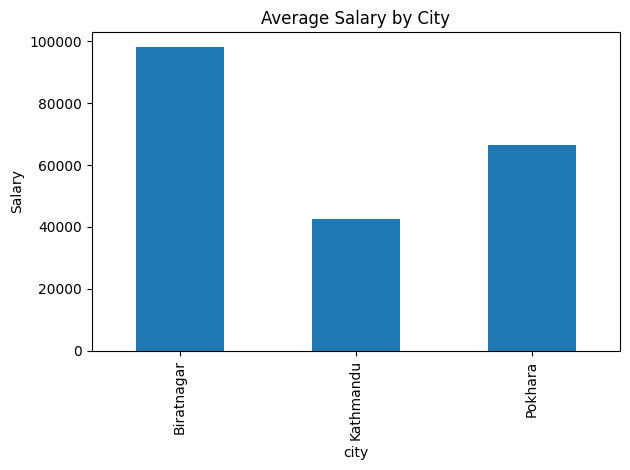

In [36]:
import matplotlib.pyplot as plt

df.groupby('city')['salary'].mean().plot(kind='bar', title='Average Salary by City', ylabel='Salary')
plt.tight_layout()
plt.show()


## 14. Exporting Data

Once you've cleaned or transformed your data, save it back out for the next step in your pipeline (modeling, reporting, sharing with teammates).


In [37]:
df.to_csv('people_processed.csv', index=False)
# Other common writers:
# df.to_excel('people.xlsx', index=False)
# df.to_json('people.json', orient='records')
# df.to_parquet('people.parquet')

print("Saved! Files in current directory:")
import os
print([f for f in os.listdir('.') if f.endswith(('.csv', '.xlsx', '.json', '.parquet'))])


Saved! Files in current directory:
['people.csv', 'people_processed.csv']


## 📌 Cheat Sheet Summary

| Task | Code |
|---|---|
| Load CSV | `pd.read_csv('file.csv')` |
| First look | `df.head()`, `df.info()`, `df.describe()` |
| Select column(s) | `df['col']`, `df[['col1','col2']]` |
| Select by label | `df.loc[rows, cols]` |
| Select by position | `df.iloc[rows, cols]` |
| Filter rows | `df[df['col'] > x]` |
| Missing values | `df.isna().sum()`, `df.dropna()`, `df.fillna(x)` |
| New column | `df['new'] = df['a'] + df['b']` |
| Custom logic | `df['col'].apply(func)` |
| Sort | `df.sort_values('col')` |
| Group & aggregate | `df.groupby('col').agg(...)` |
| Combine tables | `pd.merge(a, b, on='key', how='left')`, `pd.concat([a, b])` |
| Reshape | `df.pivot_table(...)`, `df.melt(...)` |
| Strings | `df['col'].str.upper()` |
| Dates | `pd.to_datetime(df['col'])`, `df['col'].dt.year` |
| Plot | `df.plot(kind='bar')` |
| Save | `df.to_csv('out.csv', index=False)` |

### Where to go next
- Practice on a real dataset (e.g. Kaggle datasets, or `seaborn.load_dataset('titanic')`)
- Learn `df.query()` for more readable filtering
- Explore `MultiIndex` for hierarchical data
- Learn about method chaining for cleaner pipelines
